# Pair 3 · Profiling attack types (clustering)
**HoneyBadger project, objective 3** · Pair 3

This notebook follows the four validation points: business understanding, data understanding, data preparation, and modeling with evaluation.

**How to run in Google Colab:** *Runtime → Run all* on a CPU runtime. Put `Train_data.csv` and `Test_data.csv` next to the notebook (drag them into the *Files* panel). Inside the repository, the CSVs go in the `data/` folder instead, and every output is written to `results/`. If they are missing, the notebook tries to download them from Kaggle, then asks you to upload them. A full run takes a few minutes.

## 1. Business understanding

**Context.** Objectives 1 and 2 answer *"is this connection an attack?"*. Once an alert fires, an analyst needs the next answer: *"what kind of attack is it?"* A SYN flood, a port scan and a logged-in exploit call for different responses (rate limiting, firewall rules, incident response).

**Problem.** The dataset only says `anomaly`; it gives no attack type. HoneyBadger's own events have no attack-type labels either. A supervised model cannot learn attack families without examples of each family.

**Objective.** Group the **11,743 attack rows** into families of similar behaviour with **unsupervised clustering**, describe each family by its average features, and map it to a MITRE ATT&CK technique **as a hypothesis**.

**Metrics.** There are no true family labels, so the quality of a clustering is measured on the data itself:

| Metric | What it measures | Better |
|---|---|---|
| Silhouette score | How much closer each point is to its own cluster than to the next one (−1 to 1) | Higher |
| Davies-Bouldin index | Average similarity between each cluster and its most similar neighbour | Lower |
| Calinski-Harabasz index | Ratio of between-cluster to within-cluster spread | Higher |
| Stability (adjusted Rand index) | Whether the same clusters come back with other seeds, other subsamples, and on the validation partition (1 = identical) | Close to 1 |

**Success criteria.** A small number of clusters (a handful an analyst can learn), clearly better than one big group on the three metrics, stable across seeds and subsamples (ARI above 0.9), and with profiles that a security analyst can name.

**What this notebook cannot prove.** The family names and MITRE techniques are interpretations of cluster profiles. They cannot be checked against true labels, because the dataset has none.

In [1]:
import hashlib
import io
import os
import time
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

SEED = 42
SILHOUETTE_SAMPLE = 3000                               # silhouette is O(n²), so it is computed on a fixed sample
K_RANGE = range(2, 11)
CHOSEN_K = 6                                           # justified in section 4.2
DBSCAN_EPS, DBSCAN_MIN_SAMPLES = 2.0, 10               # justified in section 4.2
DATASET = 'sampadab17/network-intrusion-detection'
DATASET_PAGE = f'https://www.kaggle.com/datasets/{DATASET}'
DOWNLOAD_URL = os.environ.get('HB_DATASET_URL', f'https://www.kaggle.com/api/v1/datasets/download/{DATASET}')
EXPECTED_FILES = {
    'Train_data.csv': ('1e40eb667611ab507870fc5b5ef0a844201ec094915d78d79f4665937e43b07a', 2_875_560),
    'Test_data.csv': ('a58db8c605e58411f6432dd9ab2fe10e1d768f058f5453e9e279788c7219caf8', 2_416_180),
}
# Folder layout in the repository: notebooks/ (this file), data/ (the two CSVs), results/ (outputs).
# Outside the repository (for example in Colab), the CSVs and predictions stay next to the notebook.
REPO_ROOT = next((p for p in [Path('.'), Path('..')] if (p / 'scripts' / 'run_analysis.py').exists()), None)
DATA_DIR = REPO_ROOT / 'data' if REPO_ROOT else Path('.')
RESULTS_DIR = (REPO_ROOT or Path('.')) / 'results'
PREDICTIONS_DIR = RESULTS_DIR / 'predictions' if REPO_ROOT else Path('.')
for folder in (DATA_DIR, RESULTS_DIR, PREDICTIONS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
PREDICTIONS_FILE = PREDICTIONS_DIR / 'pair3_predictions.csv'
FAMILY_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#e3b505', '#8e5bd0', '#d6457a', '#5F5E5A', '#3fb8c4',
                 '#a0522d', '#7f9c2b']
NOISE_COLOR = '#B4B2A9'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True})
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print(f'pandas {pd.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | Colab: {IN_COLAB}')

pandas 3.1.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Colab: False


### Load the data
Order of attempts: CSVs next to the notebook → Kaggle download → `kagglehub` → manual upload in Colab. Each file is then checked against its SHA-256 checksum, so the whole group analyses exactly the same data.

In [2]:
def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def save_new_file(name, data):
    target = DATA_DIR / name
    if target.exists():
        return
    tmp = target.with_name(f'{name}.part')
    tmp.write_bytes(data)
    tmp.replace(target)


def from_kaggle_zip(names):
    request = Request(DOWNLOAD_URL, headers={'User-Agent': 'honeybadger-notebook'})
    with urlopen(request, timeout=120) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    members = {Path(member).name: member for member in archive.namelist()}
    for name in names:
        save_new_file(name, archive.read(members[name]))


def from_kagglehub(names):
    import kagglehub
    folder = Path(kagglehub.dataset_download(DATASET))
    for name in names:
        save_new_file(name, next(folder.rglob(name)).read_bytes())


def from_colab_upload(names):
    if not IN_COLAB:
        raise RuntimeError('manual upload is only available in Colab')
    from google.colab import files
    print('Upload these files from the Kaggle download:', ', '.join(names))
    uploaded = files.upload()
    for name in names:
        if name in uploaded:
            save_new_file(name, uploaded[name])


def missing_files():
    return [name for name in EXPECTED_FILES if not (DATA_DIR / name).exists()]


for source in (from_kaggle_zip, from_kagglehub, from_colab_upload):
    if not missing_files():
        break
    try:
        source(missing_files())
        print(f'{source.__name__}: ok')
    except Exception as error:
        print(f'{source.__name__}: not available ({type(error).__name__}: {error})')
if missing_files():
    raise FileNotFoundError(f'Missing {missing_files()}. Download them from {DATASET_PAGE} and put them in the folder {DATA_DIR}.')
for name, (expected_sha, expected_size) in EXPECTED_FILES.items():
    actual_sha, actual_size = sha256_of(DATA_DIR / name), (DATA_DIR / name).stat().st_size
    if (actual_sha, actual_size) != (expected_sha, expected_size):
        raise ValueError(f'{name} differs from the reviewed Kaggle file (size {actual_size:,}, sha256 {actual_sha}).')
    print(f'{name}: {actual_size:,} bytes, sha256 verified')

train = pd.read_csv(DATA_DIR / 'Train_data.csv')
test = pd.read_csv(DATA_DIR / 'Test_data.csv')
features = [c for c in train.columns if c != 'class']
assert features == list(test.columns)
test = test.astype(train[features].dtypes.to_dict())

Train_data.csv: 2,875,560 bytes, sha256 verified
Test_data.csv: 2,416,180 bytes, sha256 verified


## 2. Data understanding

### 2.1 Size and structure

In [3]:
categorical = train[features].select_dtypes(exclude='number').columns.tolist()
numeric = [c for c in features if c not in categorical]
print(f'Train_data.csv: {train.shape[0]:,} rows x {train.shape[1]} columns (41 features + label "class")')
print(f'Test_data.csv:  {test.shape[0]:,} rows x {test.shape[1]} columns (same 41 features, no label)')
print(f'{len(categorical)} categorical features: {categorical}; {len(numeric)} numeric features')
print('Missing values in train / test:', int(train.isna().sum().sum()), '/', int(test.isna().sum().sum()))
print('Smallest numeric value in train:', train[numeric].min().min(), '(no negatives, so log1p is safe)')

Train_data.csv: 25,192 rows x 42 columns (41 features + label "class")
Test_data.csv:  22,544 rows x 41 columns (same 41 features, no label)
3 categorical features: ['protocol_type', 'service', 'flag']; 38 numeric features
Missing values in train / test: 0 / 0
Smallest numeric value in train: 0.0 (no negatives, so log1p is safe)


### 2.2 What the features mean
One row is one network connection. The 41 features come from the KDD intrusion-detection format and fall into four groups:

| Group | Features | Meaning |
|---|---|---|
| Basic | `duration`, `protocol_type`, `service`, `flag`, `src_bytes`, `dst_bytes`, `land`, `wrong_fragment`, `urgent` | Connection length, protocol (tcp/udp/icmp), target service (http, ssh, …), TCP status flag, bytes sent each way, malformed-packet indicators |
| Content | `hot`, `num_failed_logins`, `logged_in`, `num_compromised`, `root_shell`, `su_attempted`, `num_root`, `num_file_creations`, `num_shells`, `num_access_files`, `num_outbound_cmds`, `is_host_login`, `is_guest_login` | What happened inside the session: failed logins, successful login, root access, files created |
| Time-based traffic (last 2 seconds) | `count`, `srv_count`, `serror_rate`, `srv_serror_rate`, `rerror_rate`, `srv_rerror_rate`, `same_srv_rate`, `diff_srv_rate`, `srv_diff_host_rate` | How many recent connections went to the same host or service, and what share had SYN (`serror`) or REJ (`rerror`) errors |
| Host-based (last 100 connections) | `dst_host_count`, `dst_host_srv_count`, `dst_host_same_srv_rate`, `dst_host_diff_srv_rate`, `dst_host_same_src_port_rate`, `dst_host_srv_diff_host_rate`, `dst_host_serror_rate`, `dst_host_srv_serror_rate`, `dst_host_rerror_rate`, `dst_host_srv_rerror_rate` | The same statistics over a longer window, which catches slow scans |

The label `class` is `normal` or `anomaly`. The dataset does not give the attack type.

### 2.3 The attack rows
Clustering is applied to attacks only: the question is *which kind* of attack, not *whether* it is one. The charts show how the attack rows split by protocol, TCP flag and service.

11,743 attack rows (46.6% of the labeled data)
Attack rows with at least one failed login: 11 (0.09%)
Most skewed numeric features in attack rows: {'urgent': 108.4, 'num_shells': 108.4, 'land': 108.4, 'src_bytes': 108.0}


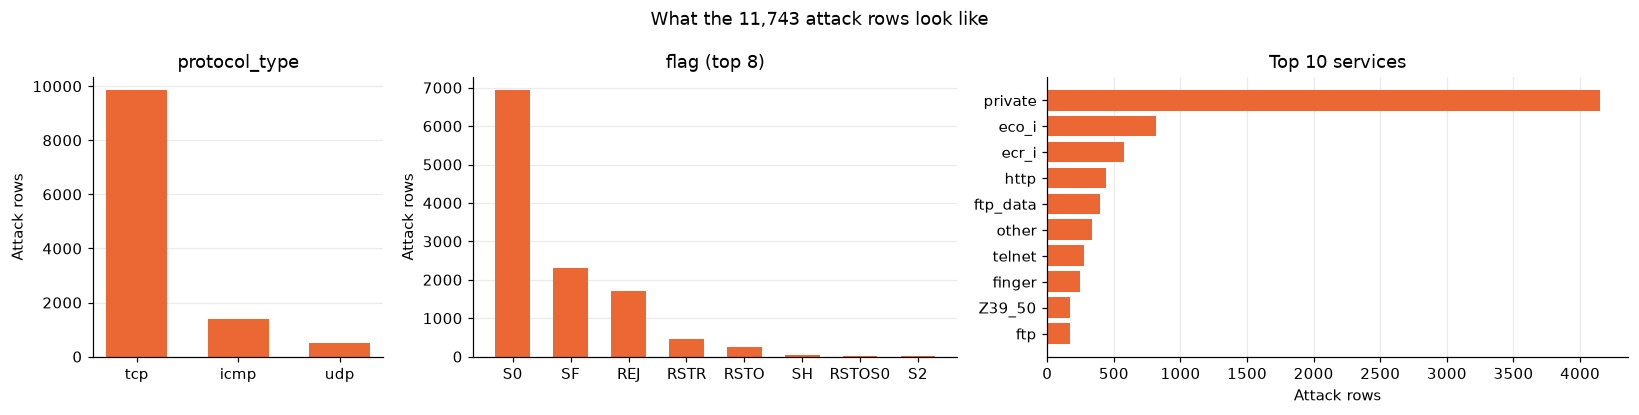

In [4]:
attacks = train[train['class'] == 'anomaly']
print(f'{len(attacks):,} attack rows ({len(attacks) / len(train):.1%} of the labeled data)')
failed = (attacks['num_failed_logins'] > 0).sum()
print(f'Attack rows with at least one failed login: {failed} ({failed / len(attacks):.2%})')
print('Most skewed numeric features in attack rows:', attacks[numeric].skew().sort_values(ascending=False).head(4).round(1).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={'width_ratios': [0.6, 1, 1.2]})
for ax, column, top in zip(axes, ['protocol_type', 'flag', 'service'], [3, 8, 10]):
    counts = attacks[column].value_counts().head(top)
    if column == 'service':
        ax.barh(counts.index[::-1], counts.values[::-1], color='#eb6834')
        ax.set(xlabel='Attack rows', title=f'Top {top} services')
        ax.grid(axis='y', visible=False)
    else:
        ax.bar(counts.index, counts.values, color='#eb6834', width=0.6)
        ax.set(ylabel='Attack rows', title=f'{column}' + (f' (top {top})' if column == 'flag' else ''))
        ax.grid(axis='x', visible=False)
fig.suptitle('What the 11,743 attack rows look like')
fig.tight_layout()
plt.show()

**Reading the charts.** Most attacks use TCP, and the `S0` flag (a connection request that never got a reply) dominates: a first hint of SYN floods. `REJ` (refused connections) suggests scanning. Many rows go to the `private` service or to ICMP echo services (`ecr_i`, `eco_i`), typical of floods and host sweeps.

Failed logins are very rare among the attacks (printed above), so a separate password-guessing family is not expected in this data. The byte counts are extremely skewed, which the preparation has to handle.

## 3. Data preparation

| Step | Decision | Why |
|---|---|---|
| Rows | **Attack rows only** (`class == anomaly`) | The business question is about attack families |
| Missing values | None to treat | Section 2.1 found 0 missing cells |
| Constant columns | Drop `num_outbound_cmds` and `is_host_login` | One value only, so no information |
| Validation split | The same grouped 80/20 split as the other notebooks (fold 0) | Results are comparable across the group; identical feature vectors never span the two partitions. The clusters are learned on the training partition and checked on the validation attacks (section 4.5) |
| Label | Never used as a feature | It is `anomaly` for every row here anyway |
| Categorical encoding | One-hot encoding of `protocol_type`, `service`, `flag`; values seen in under 1% of training attack rows are grouped as "infrequent" | Keeps the number of columns small, which matters for distance-based clustering |
| Skew | `log1p` on every numeric feature | Byte counts and durations are extremely skewed (section 2.3); otherwise one huge value would decide the distances |
| Scaling | Standard scaling, fitted on the training-partition attacks only | K-Means, GMM and DBSCAN all use distances, so no feature should dominate because of its units |
| Dimensionality | PCA for the 2D pictures; the clustering uses all prepared columns | Section 3 shows two components keep under half of the variance, too little to cluster on; 67 columns is small enough to cluster directly |

Dropped constant columns: ['num_outbound_cmds', 'is_host_login']


,attack rows,used for
training partition,9394,learning the clusters
validation partition,2349,checking that the clusters generalise


Prepared matrix: 67 columns (31 one-hot + 36 numeric)
Two principal components keep 42.1% of the variance; 14 components are needed for 90%.


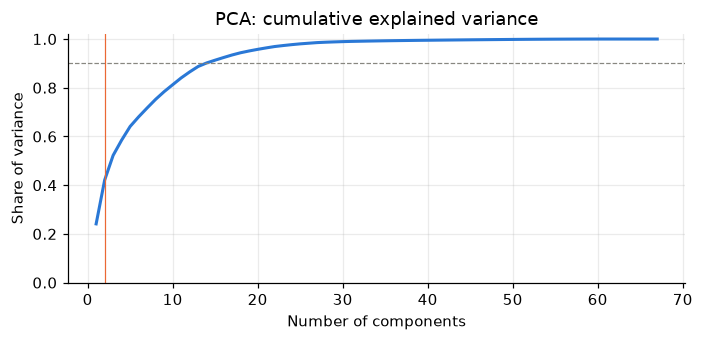

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

constant = [c for c in features if train[c].nunique() == 1]
model_features = [c for c in features if c not in constant]
categorical = [c for c in categorical if c in model_features]
numeric = [c for c in model_features if c not in categorical]
print('Dropped constant columns:', constant)

X = train[model_features]
y = (train['class'] == 'anomaly').astype(int).to_numpy()   # used only to select the attack rows


def vector_keys(frame):
    return frame[features].astype(str).agg('|'.join, axis=1)


codes, _ = pd.factorize(pd.concat([vector_keys(train), vector_keys(test)], ignore_index=True))
train_ids, test_ids = codes[:len(train)], codes[len(train):]


def grouped_stratified_folds(groups, labels, n_folds=5, seed=SEED):
    # Fold number per row; whole groups stay in one fold; shuffled within each class with a fixed seed.
    frame = pd.DataFrame({'group': groups, 'label': np.asarray(labels)})
    group_label = frame.groupby('group')['label'].agg(lambda s: sorted(s.mode())[0])
    group_size = frame.groupby('group').size()
    rng = np.random.default_rng(seed)
    group_fold = {}
    for label in sorted(group_label.unique()):
        members = group_label.index[group_label == label].to_numpy()
        members = members[rng.permutation(len(members))]
        sizes = group_size.loc[members].to_numpy()
        starts = np.cumsum(sizes) - sizes
        group_fold.update(zip(members, starts * n_folds // sizes.sum()))
    return frame['group'].map(group_fold).to_numpy()


folds = grouped_stratified_folds(train_ids, y)
fit_idx, val_idx = np.flatnonzero(folds != 0), np.flatnonzero(folds == 0)
assert not set(train_ids[fit_idx]) & set(train_ids[val_idx]), 'a feature vector is in both partitions'
attack_fit_idx, attack_val_idx = fit_idx[y[fit_idx] == 1], val_idx[y[val_idx] == 1]
X_fit, X_val = X.iloc[attack_fit_idx], X.iloc[attack_val_idx]
display(pd.DataFrame({'attack rows': [len(attack_fit_idx), len(attack_val_idx)],
                      'used for': ['learning the clusters', 'checking that the clusters generalise']},
                     index=['training partition', 'validation partition']))


def make_preprocessor(cat_cols, num_cols):
    scale = Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('scale', StandardScaler())])
    encode = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01)
    return ColumnTransformer([('cat', encode, cat_cols), ('num', scale, num_cols)], sparse_threshold=0)


prep = make_preprocessor(categorical, numeric).fit(X_fit)
Z_fit, Z_val = prep.transform(X_fit), prep.transform(X_val)
encoded = [n.split('__', 1)[1] for n in prep.get_feature_names_out()]
print(f'Prepared matrix: {Z_fit.shape[1]} columns ({Z_fit.shape[1] - len(numeric)} one-hot + {len(numeric)} numeric)')

pca = PCA(random_state=SEED).fit(Z_fit)
cumulative = np.cumsum(pca.explained_variance_ratio_)
P_fit = pca.transform(Z_fit)[:, :2]
n90 = int(np.argmax(cumulative >= 0.9) + 1)
print(f'Two principal components keep {cumulative[1]:.1%} of the variance; {n90} components are needed for 90%.')
silhouette_rows = np.random.default_rng(SEED).choice(len(Z_fit), size=min(SILHOUETTE_SAMPLE, len(Z_fit)), replace=False)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative, color='#2a78d6', linewidth=2)
ax.axhline(0.9, color='#888780', linewidth=0.8, linestyle='--')
ax.axvline(2, color='#eb6834', linewidth=0.8)
ax.set(title='PCA: cumulative explained variance', xlabel='Number of components', ylabel='Share of variance', ylim=(0, 1.02))
fig.tight_layout()
plt.show()

## 4. Modeling

### 4.1 Models and why they were chosen

| Model | How it groups connections | Why it fits this objective |
|---|---|---|
| **K-Means** | Assigns each point to the nearest of *k* centroids | Simple, fast, and each centroid is an "average attack" that is easy to describe. *k* must be chosen (section 4.2) |
| **Gaussian Mixture** (full covariance) | Fits *k* Gaussian blobs; each can have its own shape, size and orientation | Allows elongated or unequal clusters that K-Means would split. The BIC criterion is checked for *k* (section 4.2) |
| **DBSCAN** | Grows clusters from dense regions; points in sparse regions are labelled noise | Does not need *k* in advance and finds outliers. Its two settings (`eps`, `min_samples`) come from a k-distance plot |

### 4.2 Choosing the number of clusters
For K-Means, the **elbow** (inertia) and the three quality metrics are computed for *k* = 2 to 10. For the Gaussian Mixture, the **BIC** (lower is better, with a penalty for extra parameters) is computed. For DBSCAN, the **k-distance plot** shows the distance from each point to its 10th neighbour: `eps` is placed where that curve starts to climb, so most points fall inside dense regions.

,inertia,silhouette,Davies-Bouldin,Calinski-Harabasz,GMM BIC
k,,,,,
2,270289.0,0.488,1.492,2255.0,-630366.0
3,205874.0,0.507,1.311,2949.0,-1477424.0
4,176193.0,0.539,1.131,2824.0,-1590530.0
5,159374.0,0.541,0.910,2589.0,-1631649.0
6,142050.0,0.568,0.893,2553.0,-1615670.0
7,130304.0,0.575,0.819,2460.0,-1713916.0
8,119464.0,0.591,0.776,2421.0,-1777028.0
9,107774.0,0.593,0.686,2475.0,-1665331.0
10,98550.0,0.601,0.773,2504.0,-1886408.0


Lowest GMM BIC in the range: k = 10 (the edge of the range: BIC has no minimum here)
K-Means: k = 6. Gaussian Mixture: k = 6 (reasoning below).
DBSCAN: eps = 2.0 keeps 96.5% of points within eps of their 10th neighbour.


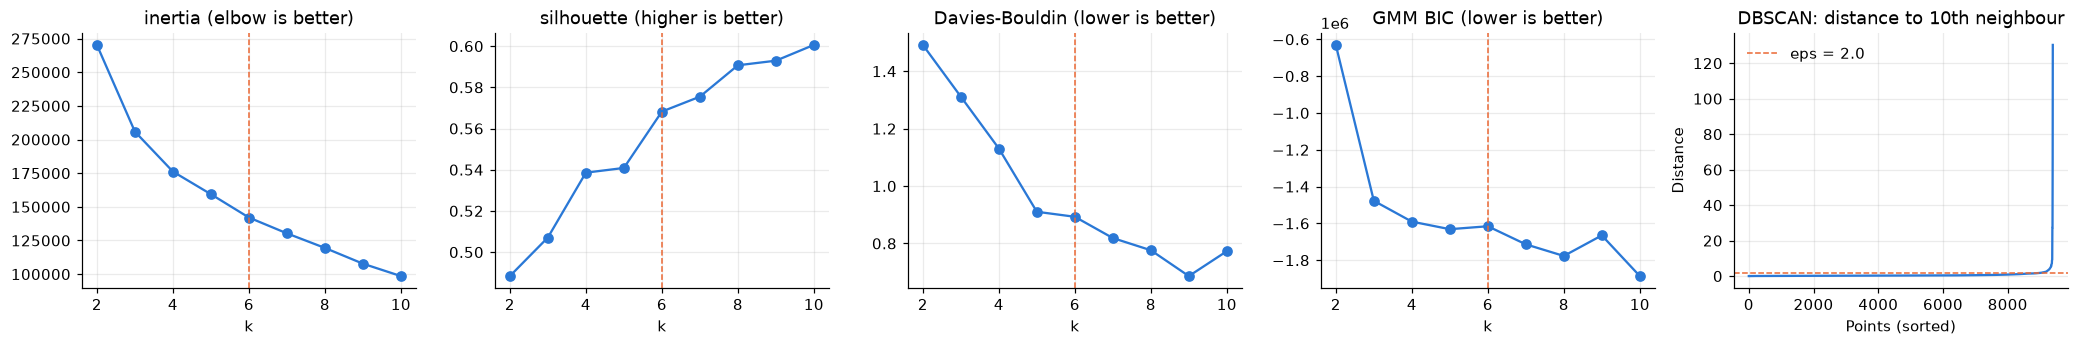

In [6]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors


def quality(Z, labels):
    keep = labels >= 0                                  # DBSCAN noise (-1) is left out of the metrics
    sample = silhouette_rows[keep[silhouette_rows]]
    return {'silhouette': silhouette_score(Z[sample], labels[sample]),
            'Davies-Bouldin': davies_bouldin_score(Z[keep], labels[keep]),
            'Calinski-Harabasz': calinski_harabasz_score(Z[keep], labels[keep])}


def make_gmm(k, seed=SEED):
    return GaussianMixture(k, covariance_type='full', reg_covar=1e-3, n_init=2, random_state=seed)


rows = []
for k in K_RANGE:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z_fit)
    gmm = make_gmm(k).fit(Z_fit)
    rows.append({'k': k, 'inertia': km.inertia_, **quality(Z_fit, km.labels_), 'GMM BIC': gmm.bic(Z_fit)})
k_table = pd.DataFrame(rows).set_index('k')
display(k_table.round({'inertia': 0, 'silhouette': 3, 'Davies-Bouldin': 3, 'Calinski-Harabasz': 0, 'GMM BIC': 0}))
bic_best = int(k_table['GMM BIC'].idxmin())
GMM_K = CHOSEN_K
print(f'Lowest GMM BIC in the range: k = {bic_best}' + (' (the edge of the range: BIC has no minimum here)' if bic_best == max(K_RANGE) else ''))
print(f'K-Means: k = {CHOSEN_K}. Gaussian Mixture: k = {GMM_K} (reasoning below).')

k_distance = np.sort(NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(Z_fit).kneighbors(Z_fit)[0][:, -1])
share_inside = (k_distance <= DBSCAN_EPS).mean()
print(f'DBSCAN: eps = {DBSCAN_EPS} keeps {share_inside:.1%} of points within eps of their {DBSCAN_MIN_SAMPLES}th neighbour.')

fig, axes = plt.subplots(1, 5, figsize=(19, 3.4))
for ax, column, better in zip(axes, ['inertia', 'silhouette', 'Davies-Bouldin', 'GMM BIC'],
                              ['elbow', 'higher', 'lower', 'lower']):
    ax.plot(k_table.index, k_table[column], color='#2a78d6', marker='o')
    chosen = GMM_K if column == 'GMM BIC' else CHOSEN_K
    ax.axvline(chosen, color='#eb6834', linewidth=1, linestyle='--')
    ax.set(title=f'{column} ({better} is better)', xlabel='k')
axes[4].plot(k_distance, color='#2a78d6')
axes[4].axhline(DBSCAN_EPS, color='#eb6834', linewidth=1, linestyle='--', label=f'eps = {DBSCAN_EPS}')
axes[4].set(title=f'DBSCAN: distance to {DBSCAN_MIN_SAMPLES}th neighbour', xlabel='Points (sorted)', ylabel='Distance')
axes[4].legend(frameon=False)
fig.tight_layout()
plt.show()

**Choice of k for K-Means.** No metric has a sharp peak: the silhouette keeps rising slowly with *k*, and Calinski-Harabasz peaks early at *k* = 3. The decision combines the curves:

* the inertia curve bends between *k* = 4 and 6, after which each extra cluster removes less spread;
* Davies-Bouldin improves strongly up to *k* = 5–6 and more slowly after;
* *k* = 6 is the smallest value at which ICMP host sweeps and ICMP/UDP floods form separate clusters (section 4.6), a difference that matters to an analyst.

Above 6, the new clusters split existing families into smaller variants, and stability drops at *k* = 8 (section 4.5). Six families are also a number an analyst can learn.

**Choice of k for the Gaussian Mixture.** The BIC keeps falling as *k* grows: with full covariance matrices over 67 columns, every extra component can fit a very tight blob, so the penalty never wins inside the range tested. The BIC therefore gives no usable answer, and the Gaussian Mixture uses the same *k* = 6 as K-Means, which also makes the two directly comparable.

**DBSCAN settings.** `min_samples = 10` asks for at least 10 nearly identical connections to form a family. `eps = 2.0` sits where the k-distance curve starts to climb, so most points are inside a dense region and only the sparse tail is noise.

### 4.3 Comparing the three models
Each model is fitted on the training-partition attacks. Clusters are numbered by size (0 = largest) so the numbering is the same on every run.

In [7]:
def by_size(labels):
    # Renumber clusters 0, 1, 2... from largest to smallest; noise (-1) stays -1. Returns new labels and the mapping.
    ids, counts = np.unique(labels[labels >= 0], return_counts=True)
    mapping = {int(old): new for new, old in enumerate(ids[np.argsort(-counts, kind='stable')])}
    mapping[-1] = -1
    return np.array([mapping[int(l)] for l in labels]), mapping


kmeans = KMeans(CHOSEN_K, n_init=10, random_state=SEED).fit(Z_fit)
gmm = make_gmm(GMM_K).fit(Z_fit)
dbscan = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES).fit(Z_fit)
labels = {}
labels['K-Means'], kmeans_map = by_size(kmeans.labels_)
labels['Gaussian Mixture'], _ = by_size(gmm.predict(Z_fit))
labels['DBSCAN'], _ = by_size(dbscan.labels_)

rows = {}
for name, lab in labels.items():
    sizes = np.bincount(lab[lab >= 0])
    rows[name] = {'clusters': len(sizes), 'noise share': (lab == -1).mean(), 'largest cluster share': sizes.max() / len(lab),
                  'clusters under 1% of rows': int((sizes < 0.01 * len(lab)).sum()), **quality(Z_fit, lab)}
model_table = pd.DataFrame(rows).T
model_table[['clusters', 'clusters under 1% of rows']] = model_table[['clusters', 'clusters under 1% of rows']].astype(int)
display(model_table.round(3))

names = list(labels)
agreement = pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in names] for a in names], index=names, columns=names)
print('Agreement between the models (adjusted Rand index, 1 = same grouping):')
display(agreement.round(3))

,clusters,noise share,largest cluster share,clusters under 1% of rows,silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means,6,0.000,0.598,1,0.568,0.893,2552.707
Gaussian Mixture,6,0.000,0.592,1,0.558,0.952,2475.946
DBSCAN,22,0.023,0.591,12,0.575,0.619,4513.823


Agreement between the models (adjusted Rand index, 1 = same grouping):


,K-Means,Gaussian Mixture,DBSCAN
K-Means,1.000,0.968,0.901
Gaussian Mixture,0.968,1.000,0.899
DBSCAN,0.901,0.899,1.000


**Reading the table.** The three models are measured with the same metrics on the same rows (DBSCAN noise excluded). The agreement table checks whether three different methods (centroids, Gaussian blobs, density) find the same groups; high agreement means the families are a property of the data, not of one algorithm.

DBSCAN follows every dense pocket of the data, so it returns many clusters, most of them under 1% of the rows. Its big clusters match the K-Means families closely (high agreement), and its noise points are the unusual attacks, but the full list is too fine-grained to brief an analyst. The Gaussian Mixture, with flexible shapes, is less stable across seeds (section 4.5). K-Means is retained for the interpretation in section 4.6 because its centroids give one readable "average attack" per family and, as section 4.5 shows, it returns the same clusters every time.

### 4.4 The clusters in two dimensions
Each point is a training-partition attack projected on the first two principal components. The projection keeps under half of the variance (section 3), so clusters that overlap here can still be well apart in the full space. Clusters are numbered by size within each model, so the same colour does not mean the same family across the three panels. For DBSCAN, only the six largest clusters get their own colour.

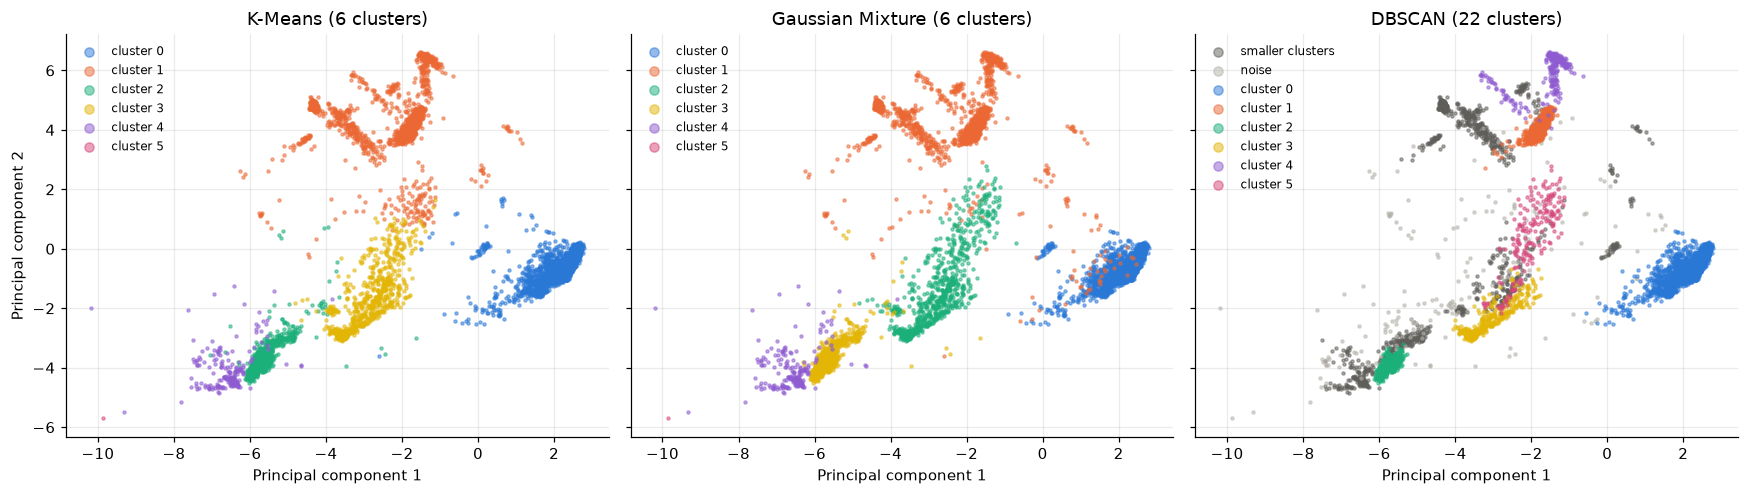

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
jitter = np.random.default_rng(SEED).normal(scale=0.05, size=P_fit.shape)   # separates identical points slightly
for ax, (name, lab) in zip(axes, labels.items()):
    small = lab >= 6                                    # beyond the 6 largest clusters: one shared grey
    if small.any():
        ax.scatter(*(P_fit[small] + jitter[small]).T, s=4, alpha=0.5, color='#5F5E5A', label='smaller clusters')
    for cluster in sorted(set(lab[~small])):
        mask = lab == cluster
        color = NOISE_COLOR if cluster == -1 else FAMILY_COLORS[cluster]
        ax.scatter(*(P_fit[mask] + jitter[mask]).T, s=4, alpha=0.5, color=color,
                   label='noise' if cluster == -1 else f'cluster {cluster}')
    ax.legend(frameon=False, markerscale=3, fontsize=8, loc='upper left')
    ax.set(title=f'{name} ({model_table.loc[name, "clusters"]} clusters)', xlabel='Principal component 1')
axes[0].set_ylabel('Principal component 2')
fig.tight_layout()
plt.show()

### 4.5 Stability
A family is only useful if it comes back every time. Three checks, all with the adjusted Rand index (ARI) against the K-Means model of section 4.3:

1. **Seeds**: refit K-Means with 10 other random seeds (and the Gaussian Mixture with 5).
2. **Subsamples**: refit on 10 random 80% subsamples, then assign every training attack.
3. **Validation partition**: assign the validation attacks with the trained model, and compare with a model fitted on the validation attacks alone. This is the clustering equivalent of a validation score.

The same seed check is also run for other values of *k*, to support the choice in section 4.2.

In [9]:
reference = labels['K-Means']
seed_ari = [adjusted_rand_score(reference, KMeans(CHOSEN_K, n_init=10, random_state=s).fit(Z_fit).labels_)
            for s in range(1, 11)]
gmm_seed_ari = [adjusted_rand_score(labels['Gaussian Mixture'], make_gmm(GMM_K, seed=s).fit(Z_fit).predict(Z_fit))
                for s in range(1, 6)]
rng = np.random.default_rng(SEED)
subsample_ari = []
for _ in range(10):
    rows_80 = rng.choice(len(Z_fit), size=int(0.8 * len(Z_fit)), replace=False)
    subsample_ari.append(adjusted_rand_score(reference, KMeans(CHOSEN_K, n_init=10, random_state=SEED).fit(Z_fit[rows_80]).predict(Z_fit)))
val_assigned = np.array([kmeans_map[int(l)] for l in kmeans.predict(Z_val)])
val_refit = KMeans(CHOSEN_K, n_init=10, random_state=SEED).fit(Z_val).labels_
validation_ari = adjusted_rand_score(val_assigned, val_refit)

stability = pd.DataFrame({'checks': [len(seed_ari), len(gmm_seed_ari), len(subsample_ari), 1],
                          'min ARI': [min(seed_ari), min(gmm_seed_ari), min(subsample_ari), validation_ari],
                          'mean ARI': [np.mean(seed_ari), np.mean(gmm_seed_ari), np.mean(subsample_ari), validation_ari]},
                         index=['K-Means, other seeds', 'Gaussian Mixture, other seeds', 'K-Means, 80% subsamples',
                                'K-Means, validation partition'])
display(stability.round(3))

shares = pd.DataFrame({'training partition': pd.Series(reference).value_counts(normalize=True).sort_index(),
                       'validation partition': pd.Series(val_assigned).value_counts(normalize=True).sort_index()}).fillna(0)
shares.index.name = 'cluster'
print('Share of attacks in each K-Means cluster:')
display(shares.round(3))

by_k = {}
for k in [4, 5, 6, 7, 8]:
    runs = [KMeans(k, n_init=10, random_state=s).fit(Z_fit).labels_ for s in range(4)]
    val_k = KMeans(k, n_init=10, random_state=SEED).fit(Z_fit).predict(Z_val)
    by_k[k] = {'min ARI across seeds': min(adjusted_rand_score(runs[0], r) for r in runs[1:]),
               'validation ARI': adjusted_rand_score(val_k, KMeans(k, n_init=10, random_state=SEED).fit(Z_val).labels_)}
print('Stability of K-Means for neighbouring values of k:')
display(pd.DataFrame(by_k).T.round(3))

,checks,min ARI,mean ARI
"K-Means, other seeds",10,0.999,1.000
"Gaussian Mixture, other seeds",5,0.870,0.889
"K-Means, 80% subsamples",10,0.937,0.987
"K-Means, validation partition",1,0.969,0.969


Share of attacks in each K-Means cluster:


,training partition,validation partition
cluster,,
0,0.598,0.573
1,0.215,0.239
2,0.083,0.082
3,0.081,0.077
4,0.022,0.029
5,0.000,0.000


Stability of K-Means for neighbouring values of k:


,min ARI across seeds,validation ARI
4,1.000,0.980
5,1.000,0.980
6,0.999,0.969
7,0.999,0.968
8,0.984,0.949


### 4.6 Interpreting the families
Each K-Means cluster is described by its size, its most common protocol, flag and services, and the average of the features that best describe network attacks. A family name and a MITRE ATT&CK technique are then attached with explicit rules on those averages, so the naming is reproducible and does not depend on cluster numbers.

| Rule (checked in this order) | Family | MITRE ATT&CK hypothesis |
|---|---|---|
| Fewer than 0.5% of the attacks | Rare outlier | Too few rows to say |
| Mean `serror_rate` > 0.7 and most common flag `S0` | SYN flood | T1499 Endpoint Denial of Service |
| Mean `rerror_rate` > 0.5 | Port scan (refused connections) | T1595 Active Scanning (also T1046) |
| Mean `num_failed_logins` > 0.1 | Password guessing | T1110 Brute Force |
| Mean `logged_in` > 0.5 | Logged-in content attack | T1190 Exploit Public-Facing Application / T1078 Valid Accounts |
| ICMP or UDP, median `count` > 50 | ICMP/UDP flood | T1498 Network Denial of Service |
| ICMP | ICMP host sweep | T1595 Active Scanning (also T1018) |
| Anything else | Unnamed family | To investigate |

**Important.** These names are hypotheses built from the cluster averages. The dataset has no attack-type labels, so they cannot be checked.

,family,MITRE hypothesis,rows,share,top protocol_type,top flag,top service
cluster,,,,,,,
0,SYN flood,T1499 Endpoint Denial of Service,5619,0.598,"tcp 100%, udp 0%","S0 99%, SH 1%, RSTOS0 0%","private 38%, telnet 3%, ftp_data 3%"
1,Port scan (refused connections),T1595 Active Scanning (also T1046),2023,0.215,"tcp 96%, udp 4%","REJ 64%, RSTR 18%, RSTO 10%","private 46%, other 12%, uucp 1%"
2,ICMP host sweep,T1595 Active Scanning (also T1018),778,0.083,"icmp 87%, tcp 13%, udp 0%","SF 99%, REJ 0%, S2 0%","eco_i 84%, ftp_data 12%, ecr_i 2%"
3,ICMP/UDP flood,T1498 Network Denial of Service,764,0.081,"icmp 58%, udp 41%, tcp 1%","SF 100%, OTH 0%, RSTR 0%","ecr_i 58%, private 39%, other 1%"
4,Logged-in content attack,T1190 Exploit Public-Facing Application / T107...,209,0.022,tcp 100%,"SF 90%, RSTR 9%, S2 1%","http 73%, ftp 21%, ftp_data 5%"
5,Rare outlier,too few rows to say,1,0.000,tcp 100%,SF 100%,telnet 100%


Average of the key features per cluster:


cluster,0,1,2,3,4,5
duration,0.00,2001.70,19.70,0.39,429.14,98.0
src_bytes,0.27,188685.42,19901.83,611.85,260319.52,621.0
dst_bytes,115.53,11.17,33116.20,2.44,6785.67,8356.0
count,170.51,160.69,1.13,229.73,2.87,1.0
srv_count,11.12,6.35,19.11,225.71,3.09,1.0
serror_rate,1.00,0.02,0.00,0.01,0.01,0.0
rerror_rate,0.00,0.93,0.00,0.00,0.07,0.0
same_srv_rate,0.11,0.28,1.00,0.93,1.00,1.0
diff_srv_rate,0.07,0.24,0.00,0.02,0.00,0.0
dst_host_count,247.07,239.51,2.61,230.16,162.00,255.0


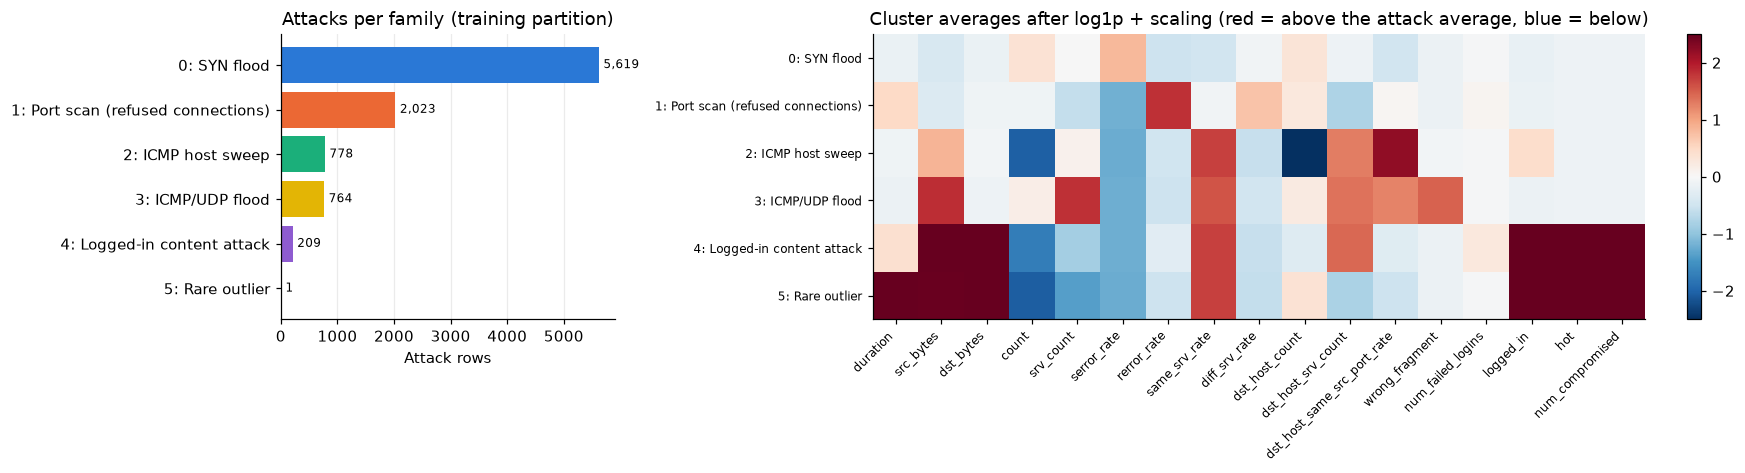

Families of the SSH and HTTP attacks (the two services HoneyBadger emulates):


service,http,other services,ssh
family,,,
ICMP host sweep,0,778,0
ICMP/UDP flood,1,763,0
Logged-in content attack,153,56,0
Port scan (refused connections),23,1992,8
Rare outlier,0,1,0
SYN flood,173,5402,44


In [10]:
KEY_FEATURES = ['duration', 'src_bytes', 'dst_bytes', 'count', 'srv_count', 'serror_rate', 'rerror_rate',
                'same_srv_rate', 'diff_srv_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_src_port_rate',
                'wrong_fragment', 'num_failed_logins', 'logged_in', 'hot', 'num_compromised']


def top_values(series, n=3):
    return ', '.join(f'{value} {share:.0%}' for value, share in series.value_counts(normalize=True).head(n).items())


def profile_clusters(frame, cluster_labels):
    grouped = frame.assign(cluster=cluster_labels).groupby('cluster')
    table = grouped[KEY_FEATURES].mean()
    table.insert(0, 'rows', grouped.size())
    table.insert(1, 'share', table['rows'] / len(frame))
    for column in ['protocol_type', 'flag', 'service']:
        table[f'top {column}'] = grouped[column].agg(top_values)
    table['main protocol'] = grouped['protocol_type'].agg(lambda s: s.mode()[0])
    table['main flag'] = grouped['flag'].agg(lambda s: s.mode()[0])
    table['median count'] = grouped['count'].median()
    return table


def name_family(row):
    if row['share'] < 0.005:
        return 'Rare outlier', 'too few rows to say'
    if row['serror_rate'] > 0.7 and row['main flag'] == 'S0':
        return 'SYN flood', 'T1499 Endpoint Denial of Service'
    if row['rerror_rate'] > 0.5:
        return 'Port scan (refused connections)', 'T1595 Active Scanning (also T1046)'
    if row['num_failed_logins'] > 0.1:
        return 'Password guessing', 'T1110 Brute Force'
    if row['logged_in'] > 0.5:
        return 'Logged-in content attack', 'T1190 Exploit Public-Facing Application / T1078 Valid Accounts'
    if row['main protocol'] in ('icmp', 'udp') and row['median count'] > 50:
        return 'ICMP/UDP flood', 'T1498 Network Denial of Service'
    if row['main protocol'] == 'icmp':
        return 'ICMP host sweep', 'T1595 Active Scanning (also T1018)'
    return 'Unnamed family', 'to investigate'


profile = profile_clusters(X_fit, reference)
profile[['family', 'MITRE hypothesis']] = profile.apply(lambda r: pd.Series(name_family(r)), axis=1)
summary_columns = ['family', 'MITRE hypothesis', 'rows', 'share', 'top protocol_type', 'top flag', 'top service']
display(profile[summary_columns].assign(share=lambda t: t['share'].round(3)))
print('Average of the key features per cluster:')
display(profile[KEY_FEATURES].T.round(2))

numeric_positions = [encoded.index(c) for c in KEY_FEATURES]
heat = pd.DataFrame(Z_fit[:, numeric_positions], columns=KEY_FEATURES).groupby(reference).mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={'width_ratios': [0.8, 2]})
order = profile.index[::-1]
axes[0].barh([f'{c}: {profile.loc[c, "family"]}' for c in order], profile.loc[order, 'rows'],
             color=[FAMILY_COLORS[c % len(FAMILY_COLORS)] for c in order])
for i, c in enumerate(order):
    axes[0].annotate(f'{int(profile.loc[c, "rows"]):,}', (profile.loc[c, 'rows'], i), xytext=(3, 0),
                     textcoords='offset points', va='center', fontsize=8)
axes[0].set(title='Attacks per family (training partition)', xlabel='Attack rows')
axes[0].grid(axis='y', visible=False)
image = axes[1].imshow(heat.clip(-2.5, 2.5).to_numpy(), cmap='RdBu_r', vmin=-2.5, vmax=2.5, aspect='auto')
axes[1].set_xticks(range(len(KEY_FEATURES)), KEY_FEATURES, rotation=45, ha='right', fontsize=8)
axes[1].set_yticks(range(len(heat)), [f'{c}: {profile.loc[c, "family"]}' for c in heat.index], fontsize=8)
axes[1].set_title('Cluster averages after log1p + scaling (red = above the attack average, blue = below)')
axes[1].grid(False)
fig.colorbar(image, ax=axes[1], fraction=0.025)
fig.tight_layout()
plt.show()

service_group = np.where(X_fit['service'].isin(['ssh', 'http']), X_fit['service'], 'other services')
print('Families of the SSH and HTTP attacks (the two services HoneyBadger emulates):')
display(pd.crosstab(pd.Series(reference).map(profile['family']).rename('family'),
                    pd.Series(service_group, name='service')))

**Reading the profiles.** Each family has a clear signature in the heat map:

* **SYN flood**: every connection ends in `S0` (no reply) and `serror_rate` is 1. Hundreds of connections hit the same host within two seconds (`count`) on many ports.
* **Port scan (refused connections)**: `rerror_rate` near 1. The target refuses the connection (`REJ`), which is what a closed port does when it is probed.
* **ICMP/UDP flood**: echo requests (`ecr_i`) or UDP repeated hundreds of times to the same service, some with malformed fragments (`wrong_fragment`).
* **ICMP host sweep**: echo requests (`eco_i`) from the same source port to very few hosts at a time. This pattern looks for live machines.
* **Logged-in content attack**: completed sessions (`SF`, `logged_in = 1`) on HTTP and FTP with large payloads and "hot" indicators (sensitive files accessed, privileges gained). These are attacks hidden inside normal-looking sessions.
* **Rare outlier**: a single extreme row, a telnet session that reached a root shell with many compromised files. It is so far from everything else that K-Means gives it its own centroid. This is an artifact of K-Means (every centroid must take some points), and DBSCAN labels such rows noise.

**SSH and HTTP.** The cross-table shows that the SSH attacks in this data are SYN floods and scans, not login attacks, and that most HTTP attacks are logged-in content attacks or SYN floods.

Password guessing does not form its own family. Only a tiny share of attacks has failed logins (section 2.3), too few for a cluster. For HoneyBadger this is the main gap: brute force (T1110) is the most common attack a honeypot sees, and HoneyBadger already labels it with rules in `backend/mitre.py`.

### 4.7 Feature selection, and the HoneyBadger question
The clustering is repeated with **HoneyBadger-compatible features** only, the same list as objectives 1 and 2: service, login outcome, and connection counts over time. Bytes, durations, TCP flags and error rates are excluded because HoneyBadger does not record them. The question is whether the same families can still be told apart.

In [11]:
HONEYBADGER_FEATURES = ['service', 'num_failed_logins', 'logged_in', 'count', 'srv_count', 'same_srv_rate',
                        'diff_srv_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
                        'dst_host_diff_srv_rate']
hb_cats = [c for c in categorical if c in HONEYBADGER_FEATURES]
hb_prep = make_preprocessor(hb_cats, [c for c in HONEYBADGER_FEATURES if c not in hb_cats]).fit(X_fit[HONEYBADGER_FEATURES])
Z_hb = hb_prep.transform(X_fit[HONEYBADGER_FEATURES])
hb_labels, _ = by_size(KMeans(CHOSEN_K, n_init=10, random_state=SEED).fit(Z_hb).labels_)
hb_quality = quality(Z_hb, hb_labels)
honeybadger_subset = pd.DataFrame({
    'All features': {'features': len(model_features), **quality(Z_fit, reference), 'ARI with full-feature families': 1.0},
    'HoneyBadger-compatible': {'features': len(HONEYBADGER_FEATURES), **hb_quality,
                               'ARI with full-feature families': adjusted_rand_score(reference, hb_labels)}}).T
honeybadger_subset['features'] = honeybadger_subset['features'].astype(int)
display(honeybadger_subset.round(3))
print('How the full-feature families are spread over the HoneyBadger-feature clusters (rows add up to 100%):')
display(pd.crosstab(pd.Series(reference).map(profile['family']).rename('family (all features)'),
                    pd.Series(hb_labels, name='HoneyBadger-feature cluster'), normalize='index').round(2))

,features,silhouette,Davies-Bouldin,Calinski-Harabasz,ARI with full-feature families
All features,39,0.568,0.893,2552.707,1.000
HoneyBadger-compatible,11,0.537,0.740,3918.766,0.566


How the full-feature families are spread over the HoneyBadger-feature clusters (rows add up to 100%):


HoneyBadger-feature cluster,0,1,2,3,4,5
family (all features),,,,,,
ICMP host sweep,0.00,0.88,0.01,0.00,0.11,0.0
ICMP/UDP flood,0.20,0.69,0.10,0.00,0.01,0.0
Logged-in content attack,0.00,0.00,0.00,0.00,1.00,0.0
Port scan (refused connections),0.55,0.00,0.23,0.21,0.00,0.0
Rare outlier,0.00,0.00,0.00,0.00,1.00,0.0
SYN flood,0.98,0.01,0.01,0.00,0.00,0.0


**Reading the result.** The ARI says how much of the full-feature grouping survives when only HoneyBadger-compatible features are available, and the cross-table shows which families get mixed:

* **SYN floods** stay together: their connection volume (many connections to one host across services) is enough to recognise them.
* **Logged-in content attacks** stay together, because `logged_in` is available.
* **ICMP host sweeps and ICMP/UDP floods merge**: without the protocol and byte counts, they only differ in volume.
* **Port scans split**, and about half of them join the SYN floods: what tells a scan from a flood is how the connection ended (`REJ` versus `S0`), and that is exactly the TCP information HoneyBadger does not record.

The metrics on the HoneyBadger features are not worse, but they measure a *different*, coarser grouping, so they cannot be compared directly with the full-feature ones.

## 5. Families for the unlabeled test file
The test file has no labels, so the attacks have to be found first. A supervised random forest (the reference model of objectives 1 and 2) is trained on all labeled rows and flags the test attacks. Then a K-Means model is refitted on **all 11,743 labeled attacks** with the same settings, and every flagged test row is assigned to its nearest family. No metric can be computed on the test file. The export keeps the original row order:

* `predicted_class`: `anomaly` or `normal`, from the random forest.
* `cluster`, `family`, `mitre_hypothesis`: filled in for predicted attacks only.
* `distance_to_centroid`: how typical the row is of its family (low = typical, high = unusual member).
* `far_from_family`: the distance is larger than for 99% of the labeled attacks of that family, so the row may be a new kind of attack.

In [12]:
from sklearn.ensemble import RandomForestClassifier

detector = Pipeline([('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), categorical)],
                                                remainder='passthrough')),
                     ('model', RandomForestClassifier(n_estimators=150, max_features=0.3, random_state=SEED, n_jobs=-1))])
detector.fit(X, y)
test_X = test[model_features]
test_attack = detector.predict(test_X) == 1

all_attacks = X[y == 1]
final_prep = make_preprocessor(categorical, numeric).fit(all_attacks)
Z_all = final_prep.transform(all_attacks)
final_kmeans = KMeans(CHOSEN_K, n_init=10, random_state=SEED).fit(Z_all)
final_labels, final_map = by_size(final_kmeans.labels_)
final_profile = profile_clusters(all_attacks, final_labels)
final_profile[['family', 'MITRE hypothesis']] = final_profile.apply(lambda r: pd.Series(name_family(r)), axis=1)
print('Families learned from all labeled attacks:')
display(final_profile[summary_columns].assign(share=lambda t: t['share'].round(3)))
same_names = sorted(final_profile['family']) == sorted(profile['family'])
print('Same family names as on the training partition:', same_names)

Z_test = final_prep.transform(test_X[test_attack])
raw_cluster = final_kmeans.predict(Z_test)
test_cluster = np.array([final_map[int(c)] for c in raw_cluster])
distance = np.linalg.norm(Z_test - final_kmeans.cluster_centers_[raw_cluster], axis=1)
train_distance = np.linalg.norm(Z_all - final_kmeans.cluster_centers_[final_kmeans.labels_], axis=1)
far_limit = pd.Series(train_distance).groupby(final_labels).quantile(0.99)   # per family, labeled attacks
far_from_family = distance > far_limit.reindex(test_cluster).to_numpy()

result = pd.DataFrame({'test_row': np.arange(len(test)),
                       'predicted_class': np.where(test_attack, 'anomaly', 'normal')})
result['cluster'] = pd.array([pd.NA] * len(test), dtype='Int64')
result.loc[test_attack, 'cluster'] = test_cluster
result['family'] = result['cluster'].map(final_profile['family'])
result['mitre_hypothesis'] = result['cluster'].map(final_profile['MITRE hypothesis'])
result['distance_to_centroid'] = np.nan
result.loc[test_attack, 'distance_to_centroid'] = distance.round(4)
result['far_from_family'] = False
result.loc[test_attack, 'far_from_family'] = far_from_family
result.to_csv(PREDICTIONS_FILE, index=False)
check = pd.read_csv(PREDICTIONS_FILE)
assert len(check) == len(test) and check['test_row'].tolist() == list(range(len(test)))
print(f'Saved {len(check):,} rows to {PREDICTIONS_FILE}; {int(test_attack.sum()):,} predicted attacks were given a family.')
test_families = result.loc[test_attack, 'family'].value_counts()
display(test_families.to_frame('test attacks').assign(share=(test_families / test_families.sum()).round(3)))
print(f'{far_from_family.mean():.1%} of predicted test attacks are farther from their family centre than 99% of the labeled '
      'attacks of that family: they may be attack types the labeled data does not contain.')

if (PREDICTIONS_DIR / 'pair1_predictions.csv').exists():
    supervised = pd.read_csv(PREDICTIONS_DIR / 'pair1_predictions.csv')
    if len(supervised) == len(result):
        agree = (supervised['predicted_class'].to_numpy() == result['predicted_class'].to_numpy()).mean()
        print(f'Agreement with the attack flags of objective 1 (pair1_predictions.csv): {agree:.1%} of test rows.')
if IN_COLAB:
    from google.colab import files
    files.download(str(PREDICTIONS_FILE))

Families learned from all labeled attacks:


,family,MITRE hypothesis,rows,share,top protocol_type,top flag,top service
cluster,,,,,,,
0,SYN flood,T1499 Endpoint Denial of Service,6964,0.593,"tcp 100%, udp 0%","S0 99%, SH 1%, RSTOS0 0%","private 37%, telnet 3%, ftp_data 3%"
1,Port scan (refused connections),T1595 Active Scanning (also T1046),2586,0.220,"tcp 95%, udp 5%, icmp 0%","REJ 66%, RSTR 17%, RSTO 10%","private 46%, other 12%, uucp 2%"
2,ICMP host sweep,T1595 Active Scanning (also T1018),966,0.082,"icmp 87%, tcp 13%, udp 0%","SF 99%, REJ 0%, S2 0%","eco_i 84%, ftp_data 12%, ecr_i 3%"
3,ICMP/UDP flood,T1498 Network Denial of Service,943,0.080,"icmp 59%, udp 40%, tcp 1%","SF 100%, OTH 0%, RSTR 0%","ecr_i 58%, private 38%, other 2%"
4,Logged-in content attack,T1190 Exploit Public-Facing Application / T107...,283,0.024,tcp 100%,"SF 90%, RSTR 8%, S2 1%","http 70%, ftp 22%, ftp_data 6%"
5,Rare outlier,too few rows to say,1,0.000,tcp 100%,SF 100%,telnet 100%


Same family names as on the training partition: True
Saved 22,544 rows to ..\results\predictions\pair3_predictions.csv; 8,589 predicted attacks were given a family.


,test attacks,share
family,,
Port scan (refused connections),4664,0.543
SYN flood,1799,0.209
ICMP/UDP flood,1246,0.145
ICMP host sweep,473,0.055
Logged-in content attack,404,0.047
Rare outlier,3,0.000


8.7% of predicted test attacks are farther from their family centre than 99% of the labeled attacks of that family: they may be attack types the labeled data does not contain.
Agreement with the attack flags of objective 1 (pair1_predictions.csv): 99.9% of test rows.


### Save the results
The settings and every measured number are written to `results/pair3_results.json`. `scripts/run_analysis.py` re-runs this notebook and compares that file with the reference values.

In [13]:
import json
import platform

RESULTS_DIR.mkdir(exist_ok=True)
to_plain = lambda o: o.item() if hasattr(o, 'item') else str(o)
families = profile[['family', 'MITRE hypothesis', 'rows', 'share']].copy()
families['share'] = families['share'].round(4)
families.index = families.index.astype(str)
record = {
    'notebook': 'notebooks/pair3_attack_profiling.ipynb',
    'environment': {'python': platform.python_version(), 'pandas': pd.__version__,
                    'scikit-learn': sklearn.__version__, 'numpy': np.__version__},
    'data': {name: {'sha256': sha, 'bytes': size} for name, (sha, size) in EXPECTED_FILES.items()},
    'config': {'seed': SEED, 'attack_rows': int(len(attacks)), 'fit_attack_rows': int(len(attack_fit_idx)),
               'validation_attack_rows': int(len(attack_val_idx)), 'prepared_columns': int(Z_fit.shape[1]),
               'silhouette_sample': int(len(silhouette_rows)), 'kmeans_k': CHOSEN_K, 'gmm_k': GMM_K,
               'dbscan': {'eps': DBSCAN_EPS, 'min_samples': DBSCAN_MIN_SAMPLES},
               'pca_2d_variance': round(float(cumulative[1]), 4), 'pca_components_for_90pct': n90},
    'k_selection': k_table.round(4).to_dict(orient='index'),
    'model_comparison': model_table.round(4).to_dict(orient='index'),
    'model_agreement_ari': agreement.round(4).to_dict(orient='index'),
    'stability': stability.round(4).to_dict(orient='index'),
    'families': families.to_dict(orient='index'),
    'honeybadger_subset': honeybadger_subset.round(4).to_dict(orient='index'),
    'test_predictions': {'rows': int(len(result)), 'predicted_anomaly': int(test_attack.sum()),
                         'families': {k: int(v) for k, v in test_families.items()},
                         'far_from_family_share': round(float(far_from_family.mean()), 4)},
}
(RESULTS_DIR / 'pair3_results.json').write_text(json.dumps(record, indent=2, sort_keys=True, default=to_plain))
print('Saved results/pair3_results.json')

Saved results/pair3_results.json


## 6. Conclusion

**Answer to the business question.** Yes. The attacks fall into **six families**, five of them meaningful to an analyst: SYN flood (about 60% of the attacks), port scan with refused connections (about 22%), ICMP host sweep and ICMP/UDP flood (about 8% each), and logged-in content attacks on HTTP and FTP (about 2%). The sixth is a single extreme row. Each family has a clear signature in its average features (section 4.6), and each maps to a MITRE ATT&CK technique as a hypothesis.

**The families are real, not an accident of one model.** Three different methods find the same grouping (ARI 0.90 to 0.97 between K-Means, Gaussian Mixture and DBSCAN, section 4.3). K-Means returns the same clusters with other seeds (ARI ≥ 0.999), on 80% subsamples (≥ 0.94), and on the validation attacks it never saw (0.97, with the same share per family, section 4.5).

**Model choice.** K-Means is kept for the profiles: its centroids are readable, it is the most stable, and its quality metrics match the alternatives. DBSCAN gives the best separation scores, but it does so by cutting the data into 22 small clusters, too many to brief an analyst. Its noise points remain useful for spotting unusual attacks. The Gaussian Mixture agrees with K-Means but is less stable across seeds, and its BIC gave no usable *k*.

**On the test file.** The predicted test attacks have a different mix: more than half are port scans, against about a fifth in the labeled data. About 9% sit far from every family centre (section 5), which suggests attack types that the labeled data does not contain. This is the expected situation for a honeypot that keeps seeing new tools.

**For HoneyBadger**
- Two families match techniques HoneyBadger already tags in `backend/mitre.py`: scans and sweeps (T1595), and logged-in content attacks (T1190 / T1078). The flood families (T1498, T1499) are network-level attacks that a honeypot at application level does not tag today.
- **Brute force (T1110) does not appear as a family**: only 11 attacks in this data have failed logins. On a real SSH honeypot, password guessing is the most common attack, so HoneyBadger's rule-based T1110 detection is still needed alongside clustering.
- With HoneyBadger-compatible features only, about half of the grouping survives (ARI 0.57, section 4.7). Floods and logged-in attacks stay recognisable, while scans and SYN floods get mixed because HoneyBadger does not record how each TCP connection ended. Recording that would be the most valuable addition, the same conclusion as objective 2.

**Limitations**
- The family names and MITRE techniques are hypotheses: the dataset has no attack-type labels to check them.
- K-Means forces every row into a family. Mixed or rare attacks (such as the single outlier) are absorbed into the nearest group.
- The clusters come from this Kaggle dataset, not from HoneyBadger's own events.
- Test-file families depend on the attack flags of the supervised random forest, so any attack it missed has no family.

**Next step.** Compute the HoneyBadger-compatible features per session from the honeypot's event log, assign each session to the nearest family, and compare the result with the MITRE technique HoneyBadger's rules already give. Where the two disagree, the session is worth a closer look.